Dataset shape: (1797, 64)
Classes: {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)}


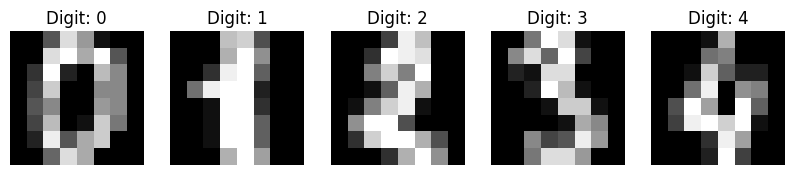

Accuracy: 98.06 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



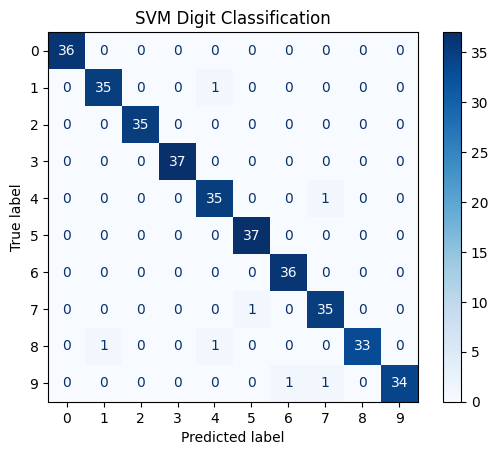


Sample Predictions:
Actual: 5 | Predicted: 5
Actual: 2 | Predicted: 2
Actual: 8 | Predicted: 8
Actual: 1 | Predicted: 1
Actual: 7 | Predicted: 7
Actual: 2 | Predicted: 2
Actual: 6 | Predicted: 6
Actual: 2 | Predicted: 2
Actual: 6 | Predicted: 6
Actual: 5 | Predicted: 5


In [1]:
#3.svm_digit_classification.ipynb
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Load handwritten digits dataset
digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Classes:", set(y))

# Display sample images
fig, axes = plt.subplots(1, 5, figsize=(10, 3))

for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Digit: {y[i]}")
    ax.axis("off")

plt.show()

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train SVM model
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale")
)

model.fit(X_train, y_train)

# Predict digits
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues"
)
plt.title("SVM Digit Classification")
plt.show()

# Display sample predictions
print("\nSample Predictions:")
for i in range(10):
    print("Actual:", y_test[i], "| Predicted:", y_pred[i])